# Lab 11 — Completed Exercises

**Student:** Abdulaziz Saqer BinRuqush  
**Student ID:** 2230007229

Instructor notebook: [Lab_11_Attention_with_RNN.ipynb](https://github.com/MohammedMosuily/NLP_lab11)  
Source commit: `5d6bfe2b8285076a4610e8c430560d811eaa0446`

Run the setup commands in the course README before running all cells.
Instructor examples and task instructions are retained below.

Changes to the instructor cells (everything else is unchanged):
- Step 1 no longer imports `google.colab.files`, and Step 2 reads the dataset from `dataset/` in this folder
  instead of a Colab upload, so the notebook runs outside Colab.
- Step 4 creates the RNN with `batch_first=True`. The instructor's `nn.RNN(16, 32)` expects (sequence, batch,
  features), but the data is (batch, sequence); the RNN therefore ran across the questions of the batch instead of
  across the words of a question, so a question's attention and prediction depended on its neighbours in the batch
  (a single question gave different results from the same question inside the full batch).
- Step 5 calls `optimizer.zero_grad()` before each backward pass. Without it PyTorch adds the gradients of all
  previous steps together, so each update uses stale gradients.


In [1]:
from pathlib import Path
import os
import random
import numpy as np

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
LAB_DIR = Path.cwd()
if not (LAB_DIR / 'Lab_11_Attention_with_RNN.ipynb').is_file():
    LAB_DIR = LAB_DIR / "Lab11"
if not (LAB_DIR / 'Lab_11_Attention_with_RNN.ipynb').is_file():
    raise FileNotFoundError("Run from the course root or this lab's folder.")
random.seed(42)
np.random.seed(42)
print("Lab 11 | Abdulaziz Saqer BinRuqush | 2230007229")

Lab 11 | Abdulaziz Saqer BinRuqush | 2230007229


# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
df = pd.read_csv(LAB_DIR / "dataset" / "Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)  # batch_first: input is (questions, words, features)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() #clear the gradients of the previous step
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


In [7]:
# Added check: how well did the trained model learn the dataset? (training data only; there is no held-out split)
with torch.no_grad():
    logits, all_weights = model(X)
train_accuracy = (logits.argmax(dim=1) == y).float().mean().item()
print(f"Final training loss: {loss.item():.4f}")
print(f"Training accuracy  : {train_accuracy:.1%} ({int((logits.argmax(dim=1) == y).sum())} of {len(y)} questions)")
print(f"Longest question has {X.shape[1]} tokens; shorter questions are padded with zeros.")

Final training loss: 0.0967
Training accuracy  : 98.2% (165 of 168 questions)
Longest question has 11 tokens; shorter questions are padded with zeros.


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

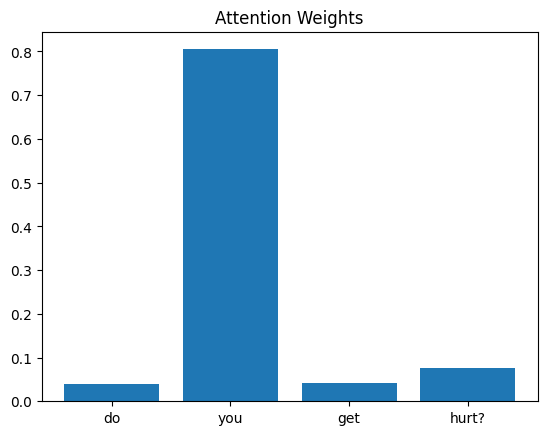

In [8]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

In [9]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

answers = df.drop_duplicates("answer_id").set_index("answer_id")["answer"].to_dict()


def attention_for(question_text):
    """Encode a question like the training data and return (words, attention on those words, answer id, answer)."""
    words = text_to_word_sequence(question_text.lower())   # same word splitting the Tokenizer uses
    ids = [tokenizer.word_index.get(word, 0) for word in words]
    padded = torch.tensor([ids + [0] * (X.shape[1] - len(ids))], dtype=torch.long)
    with torch.no_grad():
        logits, weights = model(padded)
    answer_id = int(logits.argmax(dim=1))
    return words, weights[0, :len(words)].tolist(), answer_id, answers[answer_id]


def plot_attention(question_text, axis):
    words, weights, answer_id, answer = attention_for(question_text)
    axis.bar(words, weights)
    axis.set_title(f"{question_text}\n-> answer {answer_id}: {answer}", fontsize=9)
    axis.set_ylabel("attention weight")
    axis.tick_params(axis="x", rotation=30)
    return words, weights, answer_id, answer

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

'do you get hurt?'       highest attention: 'you' (0.805) | true answer 0, predicted 0
   all weights: {'do': 0.04, 'you': 0.805, 'get': 0.042, 'hurt': 0.076}
'how old are you?'       highest attention: 'how' (0.311) | true answer 1, predicted 1
   all weights: {'how': 0.311, 'old': 0.158, 'are': 0.026, 'you': 0.074}
'what kind of food do you eat?' highest attention: 'eat' (0.528) | true answer 7, predicted 7
   all weights: {'what': 0.004, 'kind': 0.002, 'of': 0.009, 'food': 0.431, 'do': 0.014, 'you': 0.011, 'eat': 0.528}


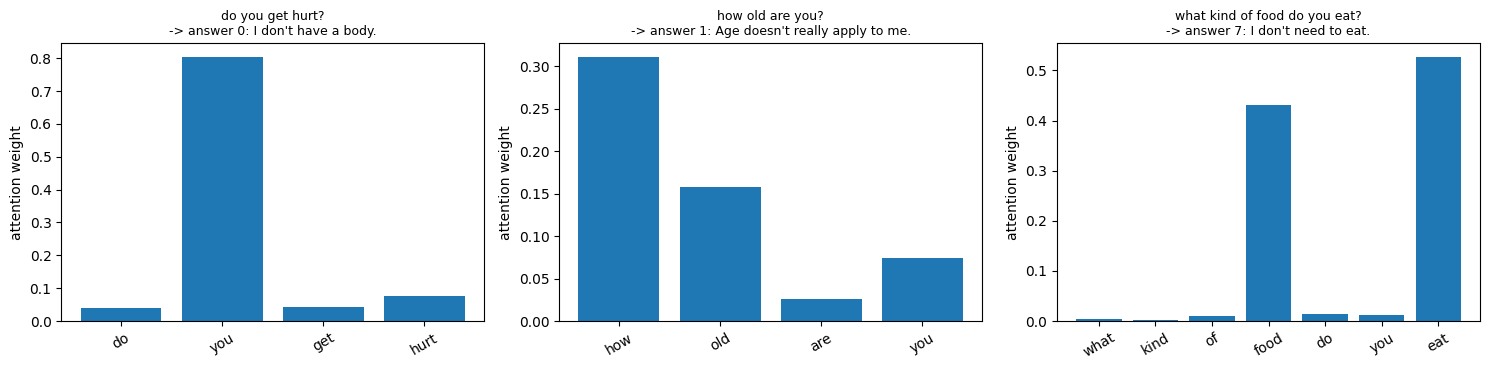

In [10]:
# Task 1: attention bar charts for three different questions (from three different answer groups).
task1_ids = [df.index[df["question"] == q][0] for q in
             ["do you get hurt?", "how old are you?", "what kind of food do you eat?"]]
task1_questions = df.loc[task1_ids, "question"].tolist()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for question_text, axis in zip(task1_questions, axes):
    words, weights, answer_id, answer = plot_attention(question_text, axis)
    top = int(np.argmax(weights))
    print(f"{question_text!r:24} highest attention: {words[top]!r} ({weights[top]:.3f}) | "
          f"true answer {int(df.loc[df['question'] == question_text, 'answer_id'].iloc[0])}, predicted {answer_id}")
    print("   all weights:", {word: round(weight, 3) for word, weight in zip(words, weights)})
plt.tight_layout()
plt.show()

**Task 1 — observations**

The three questions come from three different answer groups: *"do you get hurt?"* (answer 0, body), *"how old are you?"* (answer 1, age) and *"what kind of food do you eat?"* (answer 7, eating). The model answers all three correctly. The words with the highest attention are `you` (0.805), `how` (0.311) and `eat` (0.528).

Only some of these are the words a person would call important. In the food question, `eat` and `food` together carry about 96% of the attention, and these two words are exactly what identifies the topic. In the age question the top word is `how`, followed by `old` (0.158); `old` is the informative word, but `how` also helps because many age questions start with "how". In the hurt question the model attends mostly to `you` and gives `hurt` only 0.076, so the highest weight is not the most meaningful word there. The model has only ~170 short questions and 50 training steps, so it learns whatever words separate the 12 answer groups on this data, which is not always the word a human would pick. High attention therefore often, but not always, marks the important word. (The weights of a question add up to less than 1 because the model also spreads some attention over the zero padding positions.)

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

"what's your age?"               highest attention: 'age' (0.532) | predicted answer 1: Age doesn't really apply to me.
   all weights: {"what's": 0.152, 'your': 0.133, 'age': 0.532}
'how long have you been alive?'  highest attention: 'alive' (0.306) | predicted answer 1: Age doesn't really apply to me.
   all weights: {'how': 0.089, 'long': 0.033, 'have': 0.01, 'you': 0.111, 'been': 0.304, 'alive': 0.306}


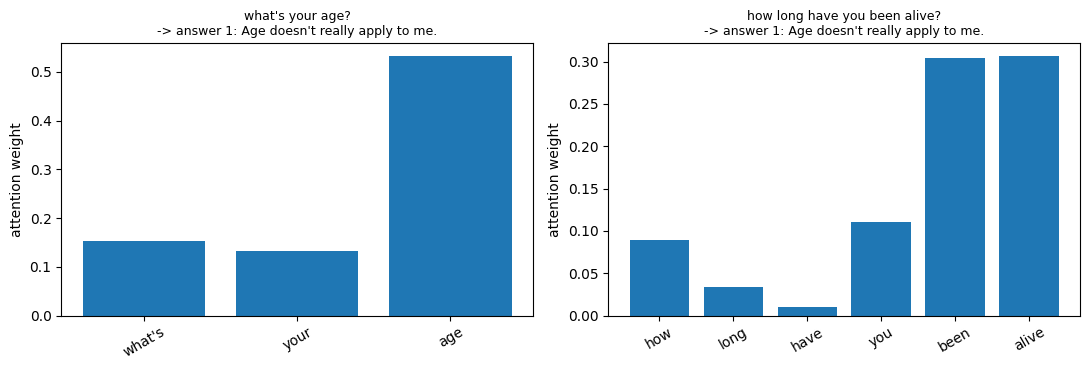

In [11]:
# Task 2: two questions with similar meaning but different wording (both ask about the assistant's age).
similar_pair = ["what's your age?", "how long have you been alive?"]
for question_text in similar_pair:
    assert question_text in set(df["question"]), question_text
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for question_text, axis in zip(similar_pair, axes):
    words, weights, answer_id, answer = plot_attention(question_text, axis)
    top = int(np.argmax(weights))
    print(f"{question_text!r:32} highest attention: {words[top]!r} ({weights[top]:.3f}) | predicted answer {answer_id}: {answer}")
    print("   all weights:", {word: round(weight, 3) for word, weight in zip(words, weights)})
plt.tight_layout()
plt.show()

**Task 2 — observations**

The pair is *"what's your age?"* and *"how long have you been alive?"*: both ask about the assistant's age and share no content words. The model gives both the same answer (answer 1, "Age doesn't really apply to me."), so it handles the two wordings as the same intent.

The attention is on different words: `age` (0.532) in the first question and `been` / `alive` (0.304 / 0.306) in the second. The model does not focus on a shared word, because there is none. It focuses on a word that signals the age topic in each wording (`age`, and `alive` together with `been` from "been alive"). This suggests that attention selects, separately for each input, the positions whose representation is most useful for the prediction, and that different surface words can lead to the same decision. The weights are a view of what the model used, not proof of why it is correct; the second question spreads its attention over two words and more weakly (max 0.306), so the model is less certain which word matters there.